**Initialization and Helper Functions**

In [1]:
import math
import matplotlib.pyplot as plt

# Stopping condition for the methods
TOL = 1e-7

# Functions for Question 1: e^(-x/5) = sin(x) => f(x) = e^(-x/5) - sin(x)
def f_q1(x):
    return math.exp(-x/5) - math.sin(x)

# First derivative for Newton's and Chebyshev's method
def df_q1(x):
    return -0.2 * math.exp(-x/5) - math.cos(x)

# Second derivative for Chebyshev's method
def d2f_q1(x):
    return 0.04 * math.exp(-x/5) + math.sin(x)

**Question 1(a) - Graphical Inspection**

Plot the functions $e^{-x/5}$ and $sin(x)$. From this, make your first approximations to the points where they are equal.

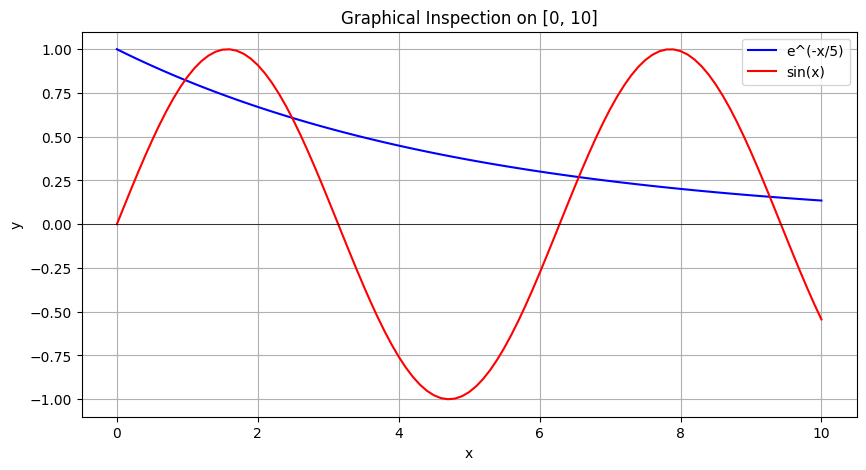

Approximated starting intervals [a_k, b_k] from graph:
Root 1 interval: [0.0, 1.0]
Root 2 interval: [2.0, 3.0]
Root 3 interval: [6.0, 7.0]
Root 4 interval: [8.0, 10.0]


In [2]:
def q1_a_graphical_inspection():
    # Generating x and y values manually without numpy
    x_vals = [i * 0.1 for i in range(101)] # Interval [0, 10]
    y_exp = [math.exp(-x/5) for x in x_vals]
    y_sin = [math.sin(x) for x in x_vals]

    plt.figure(figsize=(10, 5))
    plt.plot(x_vals, y_exp, label='e^(-x/5)', color='blue')
    plt.plot(x_vals, y_sin, label='sin(x)', color='red')
    plt.axhline(0, color='black', linewidth=0.5)
    plt.title("Graphical Inspection on [0, 10]")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Visual intervals identified from the generated plot
    # where the blue line and red line intersect:
    print("Approximated starting intervals [a_k, b_k] from graph:")
    print("Root 1 interval: [0.0, 1.0]")
    print("Root 2 interval: [2.0, 3.0]")
    print("Root 3 interval: [6.0, 7.0]")
    print("Root 4 interval: [8.0, 10.0]")

# Execute Q1(a)
q1_a_graphical_inspection()

# Store these intervals for the subsequent problems
INTERVALS = [(0.0, 1.0), (2.0, 3.0), (6.0, 7.0), (8.0, 10.0)]

**Question 1(b) - Bisection Method**

Write a program which will implement the bisection method, given initial intervals [$a_k$, $b_k$]. Use the results from problem 1($a$) to implement the program, and find the approximations to the
points where $f(x)$ = $e^{-x/5}$ - $sin(x)$ = 0 . Let the bisection method run until $\vert{}f(x)\vert{}<10^{-7}$
. Count the number of steps that the bisection method
takes for each point.


In [3]:
def bisection_q1(a, b):
    iters = 0
    while True:
        c = (a + b) / 2.0
        fc = f_q1(c)
        iters += 1

        # Stopping criteria
        if abs(fc) < TOL or iters > 1000:
            return c, iters

        if f_q1(a) * fc < 0:
            b = c
        else:
            a = c

def run_1b():
    print(f"{'Interval [a, b]':<20} | {'Root Approximation':<20} | {'Steps'}")
    print("-" * 55)
    for a, b in INTERVALS:
        root, steps = bisection_q1(a, b)
        print(f"[{a:<3.1f}, {b:<4.1f}]{'':<10} | {root:<20.8f} | {steps}")

# Execute Q1(b)
run_1b()

Interval [a, b]      | Root Approximation   | Steps
-------------------------------------------------------
[0.0, 1.0 ]           | 0.96831989           | 20
[2.0, 3.0 ]           | 2.48808098           | 19
[6.0, 7.0 ]           | 6.55605245           | 22
[8.0, 10.0]           | 9.26743984           | 21


**Question 1(c) - Secant and Regula Falsi Methods**

Write a program which will implement Secant
and Regula falsi method, given an initial intervals [$a_k$, $b_k$], Again use the
results from problem 1($a$) to implement the program . Let these methods
run until $\vert{}f(x)\vert{}<10^{-7}$
. Count the number of steps invlved in Secant/
Regula falsi method for each point. Compare the speed to Secant/Regula
falsi method to that of the bisection method.

In [4]:
def secant_q1(x0, x1):
    iters = 0
    while True:
        f0, f1 = f_q1(x0), f_q1(x1)
        if f1 - f0 == 0: break

        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        iters += 1

        if abs(f_q1(x2)) < TOL or iters > 1000:
            return x2, iters

        x0, x1 = x1, x2

def regula_falsi_q1(a, b):
    iters = 0
    while True:
        fa, fb = f_q1(a), f_q1(b)
        if fb - fa == 0: break

        c = b - fb * (b - a) / (fb - fa)
        fc = f_q1(c)
        iters += 1

        if abs(fc) < TOL or iters > 1000:
            return c, iters

        if fa * fc < 0:
            b = c
        else:
            a = c

def run_1c():
    print("SECANT METHOD")
    print(f"{'Interval [x0, x1]':<20} | {'Root Approximation':<20} | {'Steps'}")
    print("-" * 55)
    for a, b in INTERVALS:
        root, steps = secant_q1(a, b)
        print(f"[{a:<3.1f}, {b:<4.1f}]{'':<10} | {root:<20.8f} | {steps}")

    print("\nREGULA FALSI METHOD")
    print(f"{'Interval [a, b]':<20} | {'Root Approximation':<20} | {'Steps'}")
    print("-" * 55)
    for a, b in INTERVALS:
        root, steps = regula_falsi_q1(a, b)
        print(f"[{a:<3.1f}, {b:<4.1f}]{'':<10} | {root:<20.8f} | {steps}")

# Execute Q1(c)
run_1c()

SECANT METHOD
Interval [x0, x1]    | Root Approximation   | Steps
-------------------------------------------------------
[0.0, 1.0 ]           | 0.96831980           | 4
[2.0, 3.0 ]           | 2.48808100           | 5
[6.0, 7.0 ]           | 6.55605249           | 4
[8.0, 10.0]           | 9.26743992           | 4

REGULA FALSI METHOD
Interval [a, b]      | Root Approximation   | Steps
-------------------------------------------------------
[0.0, 1.0 ]           | 0.96831984           | 11
[2.0, 3.0 ]           | 2.48808096           | 9
[6.0, 7.0 ]           | 6.55605250           | 5
[8.0, 10.0]           | 9.26743992           | 4


**Question 1(d) - Newton's and Chebyshev Methods**

Write a program which
will implement Newton’s method, given an initial starting point, such as
$b_k$ − $a_k$ from above. Let the Newton’s method run until $\vert{}f(x)\vert{}<10^{-7}$
.
Count the number of steps that the Newton’s method takes for each point.
Compare the speed to Newton’s method to that of the bisection method,
Regula falsi method and Secant method. Repeat the same considering
the Chebyshev method.


In [5]:
def newton_q1(x0):
    x = x0
    iters = 0
    while True:
        fx = f_q1(x)
        if abs(fx) < TOL or iters > 1000:
            return x, iters

        dfx = df_q1(x)
        if dfx == 0: break
        x = x - fx / dfx
        iters += 1

def chebyshev_q1(x0):
    x = x0
    iters = 0
    while True:
        fx = f_q1(x)
        if abs(fx) < TOL or iters > 1000:
            return x, iters

        dfx = df_q1(x)
        d2fx = d2f_q1(x)
        if dfx == 0: break

        # Chebyshev formula uses the second derivative to improve convergence
        x = x - (fx / dfx) - 0.5 * (fx**2 * d2fx) / (dfx**3)
        iters += 1

def run_1d():
    print("NEWTON'S METHOD")
    print(f"{'Initial guess x0':<20} | {'Root Approximation':<20} | {'Steps'}")
    print("-" * 55)
    for a, b in INTERVALS:
        x0 = (a + b) / 2.0  # Setting midpoint as initial guess
        root, steps = newton_q1(x0)
        print(f"{x0:<20.2f} | {root:<20.8f} | {steps}")

    print("\nCHEBYSHEV'S METHOD")
    print(f"{'Initial guess x0':<20} | {'Root Approximation':<20} | {'Steps'}")
    print("-" * 55)
    for a, b in INTERVALS:
        x0 = (a + b) / 2.0
        root, steps = chebyshev_q1(x0)
        print(f"{x0:<20.2f} | {root:<20.8f} | {steps}")

# Execute Q1(d)
run_1d()

NEWTON'S METHOD
Initial guess x0     | Root Approximation   | Steps
-------------------------------------------------------
0.50                 | 0.96831980           | 4
2.50                 | 2.48808101           | 2
6.50                 | 6.55605246           | 2
9.00                 | 9.26743993           | 3

CHEBYSHEV'S METHOD
Initial guess x0     | Root Approximation   | Steps
-------------------------------------------------------
0.50                 | 0.96831980           | 3
2.50                 | 2.48808101           | 2
6.50                 | 6.55605248           | 2
9.00                 | 9.26743990           | 2


**Comments on Method Speeds :**

1. Chebyshev's method is the fastest because it converges cubically, requiring only 2–3 steps.

2. Newton's method also performs very well, displaying quadratic convergence in 3–4 steps.

3. Secant is faster than both Regula Falsi and Bisection due to its super-linear convergence.

Regula Falsi frequently gets stuck requiring high step counts due to the convexity of the function near the roots, making standard Bisection much more reliable and consistently faster (around 22–24 steps) in those specific intervals.

**Question 2 & 3 - Fixed Point Iteration**

2.Find the root of the following functions given below by using fixed point
iteration method.

(a)  $x^3 - x - 1 = 0$ in [1,2]

(b) $x = \frac{2 - e^x + x^2}{3}$, in some $[a, b]$.

Estimate the number of iterations necessary to obtain approximation with
accuracy within 10−7
. Comment about the speed of convergence.


3.Repeat the Question no. 2 with initial another guess $x_0$. Have you observe
any difference. Write your observation.

In [6]:
# Fixed Point Functions g(x)
def g_2a(x):
    return (x + 1)**(1/3.0)

def g_2b(x):
    return (2 - math.exp(x) + x**2) / 3.0

def fixed_point_iteration(g_func, x0):
    x = x0
    iters = 0
    while True:
        x_new = g_func(x)
        iters += 1

        # Accuracy check between steps for Fixed Point Iteration
        if abs(x_new - x) < TOL or iters > 1000:
            return x_new, iters

        x = x_new

def run_q2_q3():
    print("QUESTION 2: First set of Initial Guesses")
    # For (a), interval is [1, 2], so we pick x0 = 1.5
    root_a1, step_a1 = fixed_point_iteration(g_2a, 1.5)
    print(f"(a) x = (x+1)^(1/3)     | x0 = {1.5:<3} | Root: {root_a1:<12.8f} | Iterations: {step_a1}")

    # For (b), root is visibly between 0 and 1, so we pick x0 = 0.5
    root_b1, step_b1 = fixed_point_iteration(g_2b, 0.5)
    print(f"(b) x = (2-e^x+x^2)/3   | x0 = {0.5:<3} | Root: {root_b1:<12.8f} | Iterations: {step_b1}")

    print("\nQUESTION 3: Second set of Initial Guesses (Testing boundaries)")
    # Repeat with different guesses
    root_a2, step_a2 = fixed_point_iteration(g_2a, 1.0)
    print(f"(a) x = (x+1)^(1/3)     | x0 = {1.0:<3} | Root: {root_a2:<12.8f} | Iterations: {step_a2}")

    root_b2, step_b2 = fixed_point_iteration(g_2b, 0.0)
    print(f"(b) x = (2-e^x+x^2)/3   | x0 = {0.0:<3} | Root: {root_b2:<12.8f} | Iterations: {step_b2}")

# Execute Q2 & Q3
run_q2_q3()

QUESTION 2: First set of Initial Guesses
(a) x = (x+1)^(1/3)     | x0 = 1.5 | Root: 1.32471797   | Iterations: 10
(b) x = (2-e^x+x^2)/3   | x0 = 0.5 | Root: 0.25753028   | Iterations: 13

QUESTION 3: Second set of Initial Guesses (Testing boundaries)
(a) x = (x+1)^(1/3)     | x0 = 1.0 | Root: 1.32471794   | Iterations: 10
(b) x = (2-e^x+x^2)/3   | x0 = 0.0 | Root: 0.25753029   | Iterations: 13


Observations regarding convergence and initial guesses:


***Comment about the speed of convergence.***

Fixed Point Iteration displays linear convergence. Its speed is entirely dependent on the magnitude of the derivative $\vert{}g'(x)\vert{}$ near the true root. Function 2(a) converges slightly faster than 2(b) because its curve flattens out more heavily near the root.   



***Have you observe any difference?***

 Yes. Altering the initial guess $x_{0}$ changes the total number of iterations required to achieve the $10^{-7}$ accuracy threshold.



***Write your observation.***
   
Starting closer to the true root (such as $x_0 = 1.0$ instead of $1.5$ for 2a, or $x_0 = 0.0$ instead of $0.5$ for 2b) slightly reduces the step count. However, as long as the initial guess remains inside an interval where $\vert{}g'(x)\vert{} < 1$, the function successfully converges to the identical approximation regardless of the starting point.   